# Eight cores are not eight times faster

Your laptop has several cores and your program uses one of them. This notebook
runs a statistical job on one, two, four and eight workers and measures what the
extra cores buy, shows which statistics can be computed on data that is split
across machines and which cannot, and separates the two things people mean by
"doing things at the same time".

## 1. The speedup, and its ceiling

The job is a bootstrap: 160 000 resamples of a sample of 5 000 observations,
computing the mean of each. It splits into 16 independent tasks of 10 000
resamples. The worker
function has to live in a module file, because a pool of processes imports the
function rather than sharing it; this cell writes that file.

In [1]:
%%writefile why12_worker.py
import numpy as np

def bootstrap_means(task):
    seed, n_resamples = task
    rng = np.random.default_rng(seed)
    data = np.random.default_rng(0).exponential(size=5_000)       # the same sample on every worker
    return [data[rng.integers(0, len(data), len(data))].mean() for _ in range(n_resamples)]

Overwriting why12_worker.py


In [2]:
import os, time
from multiprocessing import Pool
import numpy as np
import matplotlib.pyplot as plt
import why12_worker

tasks = [(seed, 10_000) for seed in range(16)]
workers = [w for w in [1, 2, 4, 8] if w <= os.cpu_count()]
times = {}
for w in workers:
    t0 = time.perf_counter()
    with Pool(w) as pool:
        results = pool.map(why12_worker.bootstrap_means, tasks)
    times[w] = time.perf_counter() - t0
    print(f"{w} worker(s): {times[w]:5.2f} s   speedup {times[1] / times[w]:.2f}x")
print("bootstrap 95% interval of the mean:", np.percentile(np.concatenate(results), [2.5, 97.5]).round(4))

1 worker(s):  3.28 s   speedup 1.00x


2 worker(s):  1.76 s   speedup 1.86x


4 worker(s):  1.08 s   speedup 3.04x


8 worker(s):  1.01 s   speedup 3.25x
bootstrap 95% interval of the mean: [0.9864 1.0435]


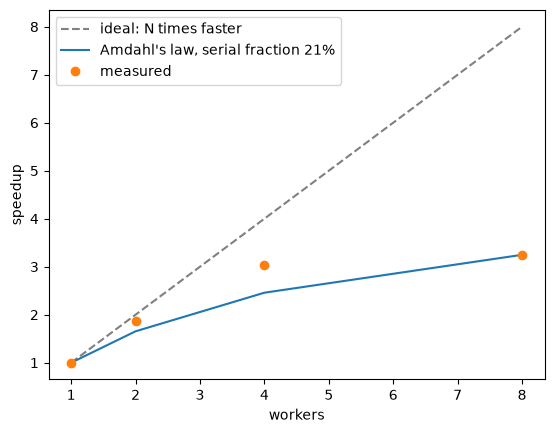

ceiling with unlimited workers: 4.8x


In [3]:
speedup = [times[1] / times[w] for w in workers]
serial = (times[workers[-1]] / times[1] - 1 / workers[-1]) / (1 - 1 / workers[-1])   # Amdahl's law, solved for the serial fraction
amdahl = [1 / (serial + (1 - serial) / n) for n in workers]

plt.plot(workers, workers, "--", color="gray", label="ideal: N times faster")
plt.plot(workers, amdahl, "-", label=f"Amdahl's law, serial fraction {serial:.0%}")
plt.plot(workers, speedup, "o", label="measured")
plt.xlabel("workers"); plt.ylabel("speedup"); plt.legend(); plt.show()
print(f"ceiling with unlimited workers: {1 / serial:.1f}x")

On an idle machine with enough cores, two workers nearly halve the time, four do
not quarter it, and eight are well short of eight times faster; if your machine
has fewer cores or is busy with something else, the speedups are smaller still.
The reason is the part of the job that is not parallel:
starting the processes, sending the tasks, collecting the results, and the memory
bandwidth that all cores share. Amdahl's law with a serial fraction fitted from the
last point reproduces the curve, and it says where it ends: the printed ceiling is
all that this serial fraction allows with unlimited workers, and a serial fraction
of ten percent caps every program at tenfold. Buying cores is the wrong fix for a
program whose serial part is large; the fix is to shrink that part.

## 2. Statistics that can be split, and one that cannot

The data is now spread over four machines, one per country, in chunks of very
different sizes and with different typical values of $x$, and we want the mean,
the standard deviation and Pearson's correlation of the whole dataset. Each
machine can compute its own statistic and send it; can the results be combined?

In [4]:
rng = np.random.default_rng(3)
sizes, shifts = [70_000, 20_000, 9_000, 1_000], [0.0, 1.0, 2.0, 4.0]     # one machine per country
chunks = []
for size, shift in zip(sizes, shifts):
    cx = rng.normal(size=size) + shift
    chunks.append((cx, 0.6 * cx + rng.normal(size=size)))
x = np.concatenate([cx for cx, _ in chunks]); y = np.concatenate([cy for _, cy in chunks])

# averaging the local statistics
print(f"mean of local means:               {np.mean([cx.mean() for cx, _ in chunks]):8.4f}   truth {x.mean():8.4f}")
print(f"mean of local std deviations:      {np.mean([cx.std() for cx, _ in chunks]):8.4f}   truth {x.std():8.4f}")
print(f"mean of local correlations:        {np.mean([np.corrcoef(cx, cy)[0, 1] for cx, cy in chunks]):8.4f}   truth {np.corrcoef(x, y)[0, 1]:8.4f}")

# combining the sums each machine sends: n, sum x, sum y, sum x^2, sum y^2, sum xy
sums = np.array([[len(cx), cx.sum(), cy.sum(), (cx**2).sum(), (cy**2).sum(), (cx * cy).sum()] for cx, cy in chunks])
n, sx, sy, sxx, syy, sxy = sums.sum(axis=0)
mean = sx / n
std = np.sqrt(sxx / n - mean**2)
r = (n * sxy - sx * sy) / (np.sqrt(n * sxx - sx**2) * np.sqrt(n * syy - sy**2))
print(f"from combined sums:  mean {mean:.4f}   std {std:.4f}   correlation {r:.4f}")

mean of local means:                 1.7411   truth   0.4202
mean of local std deviations:        0.9954   truth   1.2380
mean of local correlations:          0.5129   truth   0.5946
from combined sums:  mean 0.4202   std 1.2380   correlation 0.5946


Averaging local means is wrong because the chunks have different sizes, and
averaging local standard deviations or correlations is wrong for a deeper reason:
neither is a linear function of the data, and the variation between countries,
which is part of the whole dataset, is invisible inside every chunk. What every machine can send instead is
the six sums that all three formulas are made of, and sums add up exactly. The
combined values match the truth to the last digit. This is the reduce step of
MapReduce applied to statistics: send sufficient statistics, not results. A median
has no such sums, which is why it needs the whole data or several rounds of
communication.

## 3. Waiting in parallel versus computing in parallel

Twenty downloads that each take a tenth of a second, and four computations that
each take a fraction of a second, both run first one after the other and then in
twenty or four threads. Threads in Python share one interpreter and only one of
them executes Python code at a time; see which job benefits.

In [5]:
import time
from concurrent.futures import ThreadPoolExecutor

def download(i):                       # waiting for the network: the CPU is idle
    time.sleep(0.1)
    return i

def compute(i):                        # the CPU is busy the whole time
    return sum(k * k for k in range(3_000_000))

for name, job, n in [("waiting", download, 20), ("computing", compute, 4)]:
    t0 = time.perf_counter(); [job(i) for i in range(n)]; t_seq = time.perf_counter() - t0
    t0 = time.perf_counter()
    with ThreadPoolExecutor(n) as ex:
        list(ex.map(job, range(n)))
    t_thr = time.perf_counter() - t0
    print(f"{name:<10} sequential {t_seq:.2f} s   {n} threads {t_thr:.2f} s")

waiting    sequential 2.00 s   20 threads 0.11 s


computing  sequential 0.42 s   4 threads 0.43 s


The downloads finish about twenty times sooner with threads: while one thread
waits, another can start its own wait, so all twenty waits overlap. That is
concurrency, and it needs no extra core. The computations gain nothing from
threads, because only one thread computes at a time; running them on several cores
at once is parallelism, and in Python it takes processes, as in part 1. Knowing
which of the two your program needs is the first decision, before any hardware.

**What we used:** [Amdahl's law](../Transcripts/12-ParallelProgramming.md#11-amdahls-law),
[distributed statistical inference](../Transcripts/12-ParallelProgramming.md#10-distributed-statistical-inference),
[software parallelization and MapReduce](../Transcripts/12-ParallelProgramming.md#9-software-parallelization-and-mapreduce),
[concurrency vs parallelism](../Transcripts/12-ParallelProgramming.md#5-concurrency-vs-parallelism)
and [Moore's law and why it is running out](../Transcripts/12-ParallelProgramming.md#1-moores-law-and-why-it-is-running-out)
from session 12.